# 2 · Análisis exploratorio

¿Cuánto emite cada país, qué tan rico es y cómo evolucionaron la región y sus intensidades desde 1990?

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from IPython.display import Image, display
from desarrollo_co2 import config, descarga, limpieza, union, desacople as D, kaya, kuznets as K, graficos
from desarrollo_co2.graficos import num   # formato español: 1.234,56

pd.set_option("display.float_format", lambda v: num(v, 2))
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

In [2]:
panel = pd.read_csv(config.PANEL)
ultimo = int(panel.dropna(subset=["pib_ppa", "co2_mt"])["anio"].max())
f"{panel['iso3'].nunique() - 1} países + región · {panel['anio'].min()}–{panel['anio'].max()} · último año con PIB y CO2: {ultimo}"

'20 países + región · 1990–2024 · último año con PIB y CO2: 2024'

## 2.1 Foto del último año

In [3]:
cols = ["pais", "pib_pc_ppa", "co2_pc_t", "intensidad_co2_kg_usd", "energia_pc_mwh", "carbono_energia_kg_kwh",
        "petroleo_pct_co2", "renovable_pct_consumo"]
foto = panel[panel["anio"] == ultimo][cols].sort_values("co2_pc_t", ascending=False)
foto["renovable_pct_consumo"] = panel[panel["anio"] == 2021].set_index("pais").reindex(foto["pais"])["renovable_pct_consumo"].values
foto.rename(columns={"renovable_pct_consumo": "renovable_pct_2021"})

,pais,pib_pc_ppa,co2_pc_t,intensidad_co2_kg_usd,energia_pc_mwh,carbono_energia_kg_kwh,petroleo_pct_co2,renovable_pct_2021
699,Venezuela,NaN,"4,09",NaN,"24,59","0,17","48,46","33,70"
139,Chile,"30.267,64","3,98","0,13","26,25","0,15","69,14","24,20"
34,Argentina,"26.771,97","3,74","0,14","21,51","0,17","42,36","9,20"
454,México,"21.970,35","3,52","0,16","17,65","0,20","47,59","13,00"
279,Rep. Dominicana,"24.229,89","2,90","0,12","12,25","0,24","58,41","14,80"
524,Panamá,"36.394,92","2,80","0,08","23,11","0,12","74,48","28,00"
734,América Latina (18),"19.682,74","2,54","0,13","15,87","0,16","58,18",NaN
314,Ecuador,"13.922,42","2,54","0,18","12,72","0,20","85,96","18,90"
664,Uruguay,"32.149,48","2,35","0,07","15,80","0,15","92,55","57,80"
69,Bolivia,"11.329,15","2,31","0,20","9,38","0,25","50,62","12,80"


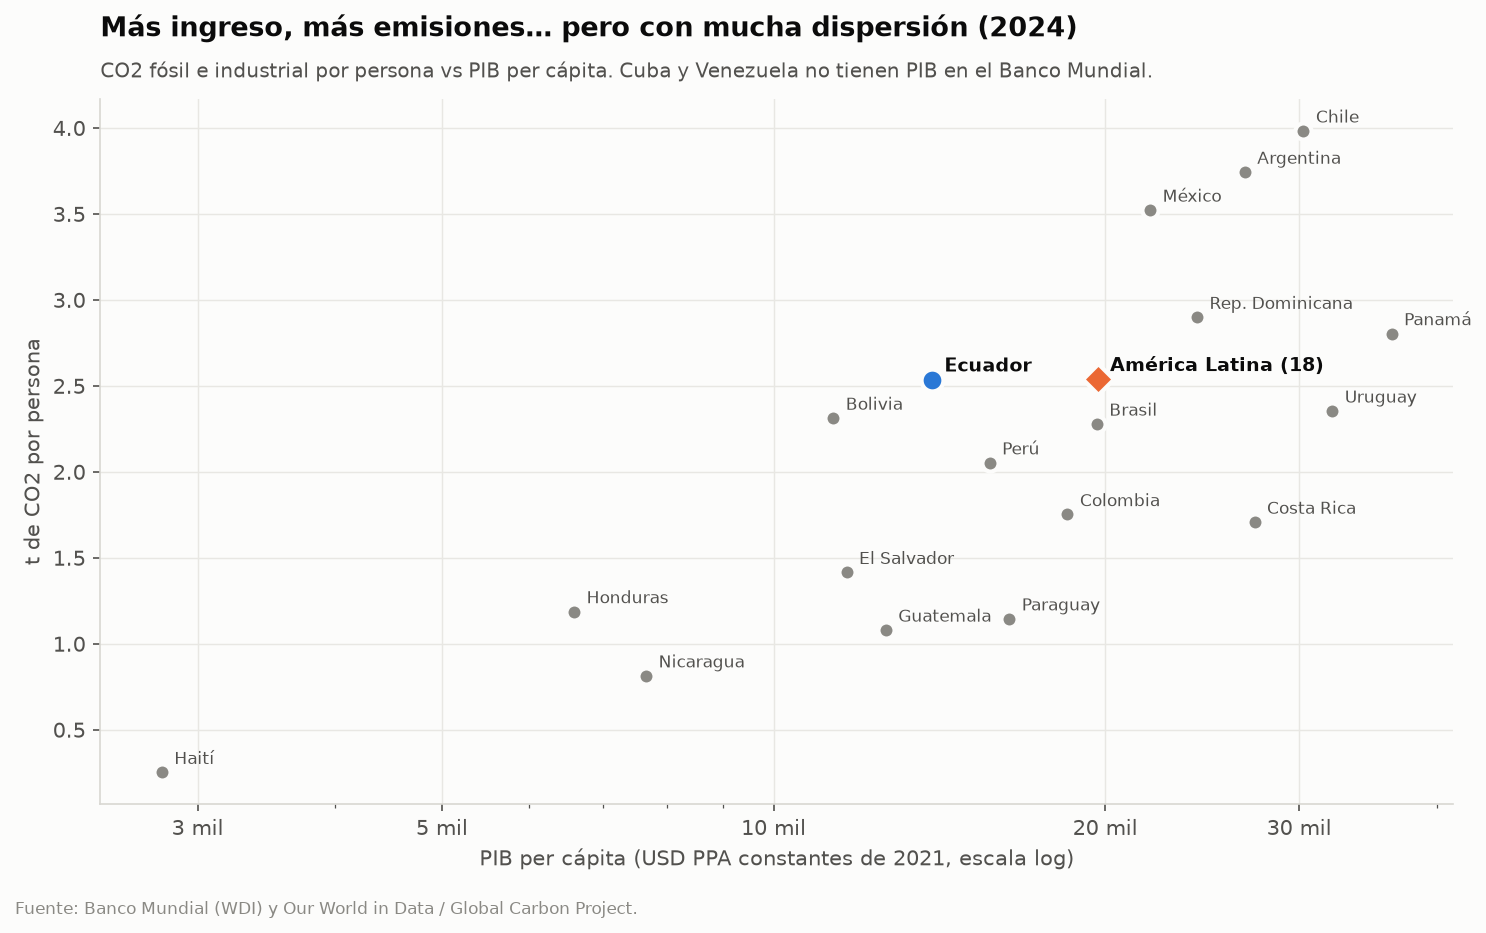

In [4]:
display(Image(config.FIGURAS / "02_co2_vs_ingreso.png"))

In [5]:
d = foto.dropna(subset=["pib_pc_ppa"])
d = d[d["pais"] != config.NOMBRE_REGION]
r = np.corrcoef(np.log(d["pib_pc_ppa"]), np.log(d["co2_pc_t"]))[0, 1]
f"Correlación entre log(PIB pc) y log(CO2 pc) en {ultimo}: r = {num(r, 2)} (n = {len(d)})"

'Correlación entre log(PIB pc) y log(CO2 pc) en 2024: r = 0,86 (n = 18)'

**Lectura:** la relación es fuerte en logaritmos (r ≈ 0,86: el ingreso explica ~74 % de la variación entre países, con Haití en un extremo), pero a igual ingreso las emisiones cambian mucho. Costa Rica y Uruguay tienen ingresos de Chile o Argentina con menos de la mitad de sus emisiones por persona: su electricidad es casi toda renovable. Ecuador emite como el promedio regional (≈ 2,5 t por persona) con un ingreso bastante menor.

## 2.2 La región en el tiempo

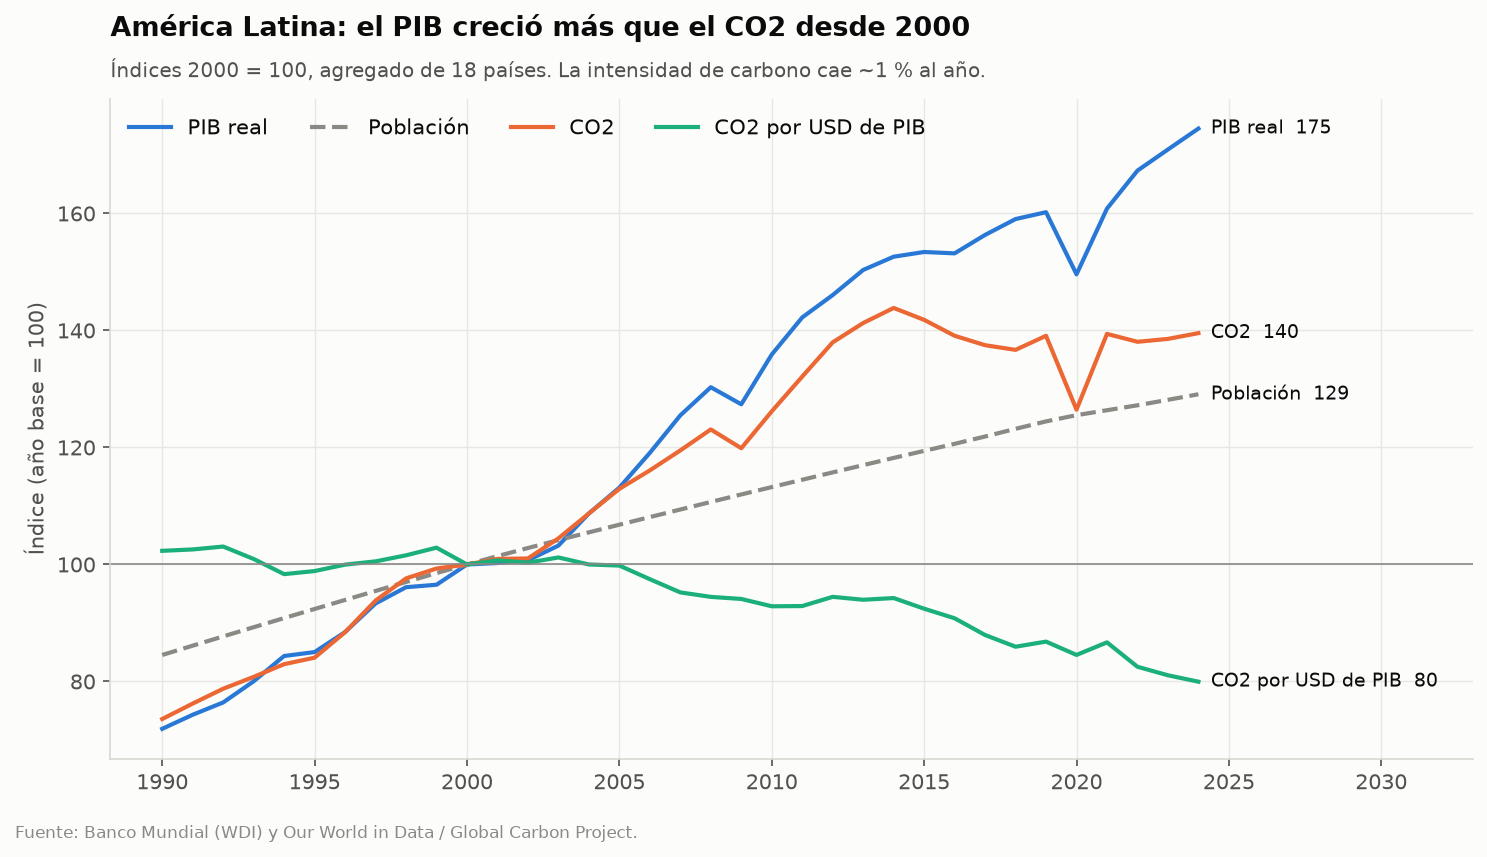

In [6]:
display(Image(config.FIGURAS / "03_region_indices.png"))

In [7]:
reg = panel[panel["iso3"] == config.REGION].set_index("anio")
tabla = reg.loc[[1990, 2000, 2010, 2019, 2020, 2024], ["pib_ppa", "co2_mt", "co2_pc_t", "intensidad_co2_kg_usd", "carbono_energia_kg_kwh"]]
tabla.assign(pib_ppa=tabla["pib_ppa"] / 1e12).rename(columns={"pib_ppa": "pib_billones_usd"})

,pib_billones_usd,co2_mt,co2_pc_t,intensidad_co2_kg_usd,carbono_energia_kg_kwh
anio,,,,,
1990,"4,96","818,51","2,04","0,17","0,19"
2000,"6,90","1.112,33","2,35","0,16","0,18"
2010,"9,37","1.403,45","2,62","0,15","0,18"
2019,"11,05","1.547,13","2,62","0,14","0,17"
2020,"10,32","1.406,70","2,37","0,14","0,17"
2024,"12,04","1.552,15","2,54","0,13","0,16"


* 1990–2000: PIB y CO2 crecieron casi a la par (intensidad constante).
* Desde 2000 el PIB se separa: la intensidad de carbono de la región baja de 0,161 a 0,129 kg por dólar (−20 %).
* El CO2 regional tocó techo en 2014 y en 2024 seguía por debajo de ese pico, aunque el PIB creció ~14 % más.
* 2020 (pandemia) bajó todo a la vez; no es desacople.

## 2.3 Composición: ¿de qué combustible viene el CO2?

In [8]:
fuentes = ["co2_petroleo_mt", "co2_gas_mt", "co2_carbon_mt", "co2_cemento_mt", "co2_quema_mt"]
mix = panel[panel["anio"] == ultimo].set_index("pais")[fuentes]
mix = (100 * mix.div(mix.sum(axis=1), axis=0)).round(1)
mix.columns = ["petróleo", "gas", "carbón", "cemento", "quema"]
mix.sort_values("petróleo", ascending=False)

,petróleo,gas,carbón,cemento,quema
pais,,,,,
Nicaragua,"96,60","0,00","0,00","3,40","0,00"
Haití,"96,40","0,00","0,00","3,60","0,00"
Paraguay,"95,60","0,00","0,00","4,40","0,00"
Costa Rica,"94,60","0,00","0,60","4,90","0,00"
Honduras,"94,40","0,00","0,00","5,60","0,00"
Uruguay,"92,50","2,90","0,10","4,50","0,00"
Cuba,"90,10","8,30","0,00","1,30","0,40"
El Salvador,"87,50","8,20","0,00","4,20","0,00"
Guatemala,"87,30","0,00","6,00","6,30","0,40"


Ecuador, Uruguay, Costa Rica, Paraguay y Centroamérica emiten casi solo por petróleo (transporte y algo de generación). Argentina, México y Bolivia tienen mucho gas; Chile y Colombia algo de carbón.

## 2.4 Emisiones territoriales vs de consumo

In [9]:
c = panel[(panel["anio"] == 2023) & panel["comercio_neto_co2_pct"].notna()][["pais", "co2_mt", "co2_consumo_mt", "comercio_neto_co2_pct"]]
c.sort_values("comercio_neto_co2_pct")

,pais,co2_mt,co2_consumo_mt,comercio_neto_co2_pct
698,Venezuela,"119,59","100,52","-15,95"
383,Honduras,"12,40","10,46","-15,69"
103,Brasil,"483,99","469,99","-2,89"
33,Argentina,"178,41","185,67","4,07"
68,Bolivia,"24,62","25,63","4,09"
313,Ecuador,"44,60","48,90","9,64"
138,Chile,"77,60","88,16","13,60"
173,Colombia,"89,99","104,47","16,08"
558,Perú,"66,06","78,88","19,40"
453,México,"458,25","564,97","23,29"


`comercio_neto_co2_pct` > 0 significa que el país **consume** más CO2 del que **produce** (lo importa dentro de bienes). Casi toda la región es importadora neta de emisiones; Ecuador consume ~10 % más de lo que emite en su territorio. Esto importa para el desacople: un país puede "desacoplar" en su territorio solo porque importa lo que antes fabricaba.

## 2.5 Uso del suelo: la otra mitad del CO2

In [10]:
luc = panel[panel["anio"].isin([2000, ultimo]) & (panel["iso3"] != config.REGION)].pivot(index="pais", columns="anio", values="co2_luc_mt")
luc["fosil_" + str(ultimo)] = panel[panel["anio"] == ultimo].set_index("pais")["co2_mt"]
luc.sort_values(2000, ascending=False).head(8)

anio,2000,2024,fosil_2024
pais,,,
Brasil,"1.949,84","1.599,67","483,01"
México,"135,55","-37,24","460,99"
Bolivia,"108,99","110,94","28,71"
Nicaragua,"88,02","9,38","5,63"
Perú,"76,12","16,68","70,25"
Guatemala,"66,62","29,58","19,88"
Paraguay,"57,80","15,27","7,94"
Argentina,"54,57","144,41","171,06"


En Brasil, Bolivia y Paraguay la deforestación emitió tanto o más CO2 que los combustibles. Esas estimaciones tienen incertidumbres grandes y oscilan mucho entre años; por eso el análisis principal usa CO2 fósil + industria, y el CO2 con uso del suelo queda como prueba de robustez.